# Starter Code

- Use seed = 42

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

SEED = 42

In [ ]:
# Part 1 : Basic Graph Statistics

def graph_statistics(G: nx.Graph):
  num_nodes = G.number_of_nodes()
  num_edges = G.number_of_edges()

  # avg nearest neighbor degree of nodes
  avg_degree = sum(dict(G.degree()).values()) / num_nodes

  #TODO: calculate average clustering coefficient
  avg_clustering = nx.average_clustering(G)

  return {
      "num_nodes": num_nodes,
      "num_edges": num_edges,
      "avg_degree": avg_degree,
      "avg_clustering": avg_clustering,
  }

In [ ]:
# Part 2: Erdos-Renyi graph

def create_er_graph(n: int, p: float):
  # n = number of nodes
  # p = probability for edge creation
  G = nx.erdos_renyi_graph(n, p, seed=SEED)
  return G

In [ ]:
# Part 3: Barabasi-Albert graph

def create_ba_graph(n: int, m: int):
  # n = number of nodes
  # m = number of edges to attach from a new node to existing node
  G = nx.barabasi_albert_graph(n, m, seed=SEED)
  return G

In [ ]:
# Part 4: Watts-Strogatz graph

def create_ws_graph(n: int, k: int, p: float):
  # n = number of nodes
  # k = each node is joined with its K nearest neighbors in a ring
  # p = probability of rewiring each edge
  G = nx.watts_strogatz_graph(n, k, p, seed=SEED)
  return G

In [ ]:
# Part 5: Helper function for visualization


def visualize_graph(G: nx.Graph, title: str):
    plt.figure(figsize=(7, 7))

    pos = nx.spring_layout(G, seed=SEED)

    nx.draw(
        G,
        pos,
        node_size=30,
        with_labels=False
    )

    plt.title(title)
    plt.show()

In [ ]:
# print graph stats helper func

def print_graph_stats(G: nx.Graph):
  stats = graph_statistics(G)
  print(f'Number of nodes: {stats['num_nodes']}')
  print(f'Number of edges: {stats['num_edges']}')
  print(f'Average Degree: {stats['avg_degree']}')
  print(f'Average Clustering Coefficient {stats['avg_clustering']}')
  print(f'Number of connected components: {nx.number_connected_components(G)}')
  print(f'Size of largest connected component: {len(max(nx.connected_components(G), key=len))}')

# Part 1 - Understanding Random Graphs

1. For a graph to be generated by a random graph model means that it will be generated using randomized algorithms and different probability models.

2. Resarchers might want to compare a real network with a random network to help simulate or model something from the real-world.

3. If a fixed random seed is used when generating a random graph then that random graph would be reproducible when testing.

# Part 2 - Erdos-Renyi Random Graph

Number of nodes: 100
Number of edges: 224
Average Degree: 4.48
Average Clustering Coefficient 0.04234126984126984
Number of connected components: 1
Size of largest connected component: 100


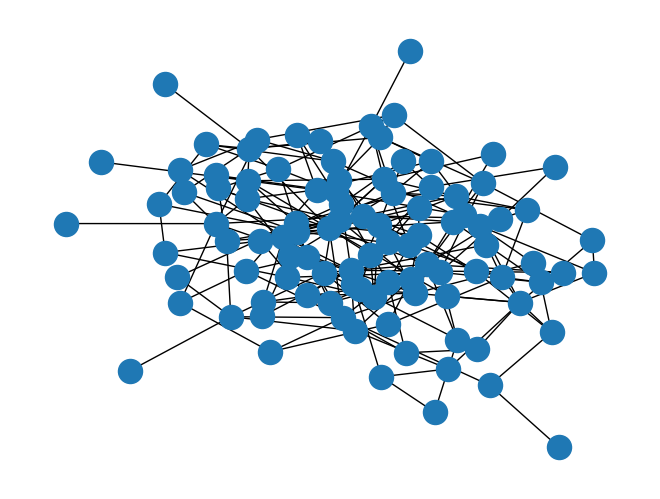

In [ ]:
n = 100
p = 0.05
seed = 42

G_er = create_er_graph(n, p)

# number of nodes
print_graph_stats(G_er)

nx.draw(G_er)

1. p=0.05 is the probability that an edge will be created for the node.

2. No, this does not mean that every node will have exactly the same number of neighbors, it just means that each pair of nodes will have a 5 percent chance to create an edge between them.

3. Yes the graph is connected.

4. I notice that the graph is very clustered in the middle and it becomes less clustered as you move away from the middle.

# Part 3 - Change the Probability

In [ ]:
n = 100
p1 = 0.01
p2 = 0.05
p3 = 0.10

G_er1 = create_er_graph(n, p1)
G_er2 = create_er_graph(n, p2)
G_er3 = create_er_graph(n, p3)

print('-'*10 + 'Graph ER 1' + '-' * 10)
print_graph_stats(G_er1)
print('='*50)
print('-'*10 + 'Graph ER 2' + '-' * 10)
print_graph_stats(G_er2)
print('='*50)
print('-'*10 + 'Graph ER 3' + '-' * 10)
print_graph_stats(G_er3)
print('='*50)

----------Graph ER 1----------
Number of nodes: 100
Number of edges: 55
Average Degree: 1.1
Average Clustering Coefficient 0.0
Number of connected components: 47
Size of largest connected component: 41
----------Graph ER 2----------
Number of nodes: 100
Number of edges: 224
Average Degree: 4.48
Average Clustering Coefficient 0.04234126984126984
Number of connected components: 1
Size of largest connected component: 100
----------Graph ER 3----------
Number of nodes: 100
Number of edges: 474
Average Degree: 9.48
Average Clustering Coefficient 0.08782348207348206
Number of connected components: 1
Size of largest connected component: 100


| p    | Edges | Average Degree | Average Clustering  | # Components | Largest Component |
|------|-------|----------------|---------------------|--------------|-------------------|
| 0.01 | 55    | 1.1            | 0.0                 | 47           | 41                |
| .05  | 224   | 4.48           | 0.04234126984126984 | 1            | 100               |
| .10  | 474   | 9.48           | 0.08782348207348206 | 1            | 100               |

1. The number of edges increase.

2. The average degree increases.

3. The clustering coefficient increases.

4. The number of connected components converged to 1.

5. Increasing p leads to more edges being created which also seems to lead to a higher level of network connectivity.

# Part 4 - Barabasi-Albert Preferential Attachment

Number of nodes: 100
Number of edges: 196
Average Degree: 3.92
Average Clustering Coefficient 0.16338786067733438
Number of connected components: 1
Size of largest connected component: 100
Maximum G_ba degree: 36
Maximum G_er degree: 10


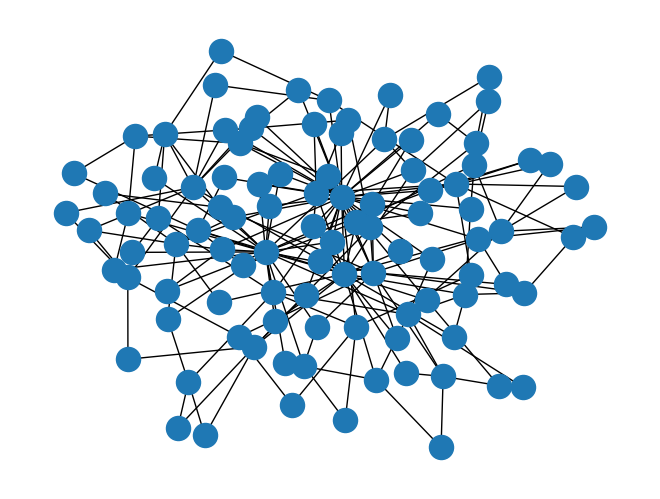

In [ ]:
n = 100
m = 2
G_ba = create_ba_graph(n, m)

print_graph_stats(G_ba)

# maximum degree
print(f'Maximum G_ba degree: {max(dict(G_ba.degree()).values())}')
print(f'Maximum G_er degree: {max(dict(G_er.degree()).values())}')
nx.draw(G_ba)

1. Preferential attachment means that a node has a higher chance of having an edge createdbased on the amount of neighbors it is attached to.

2. Yes, there are some nodes in the center that seem to have a higher connection when compared to the other nodes in the network.

3. G_ba maximum degree is 36 and the maximum degree for G_er is 10

4. Preferential attachment tends to produce highly connected nodes or hubs due to the fact that a node with a lot of neighbors will have a higher probability of being connected to the new node.  

# Part 5 - Watts-Strogatz Small-World Network

Number of nodes: 10
Number of edges: 20
Average Degree: 4.0
Average Clustering Coefficient 0.4966666666666667
Number of connected components: 1
Size of largest connected component: 10
G_ws is connected: True
Average shortest-path length: 1.6666666666666667
Maximum G_ws degree: 5


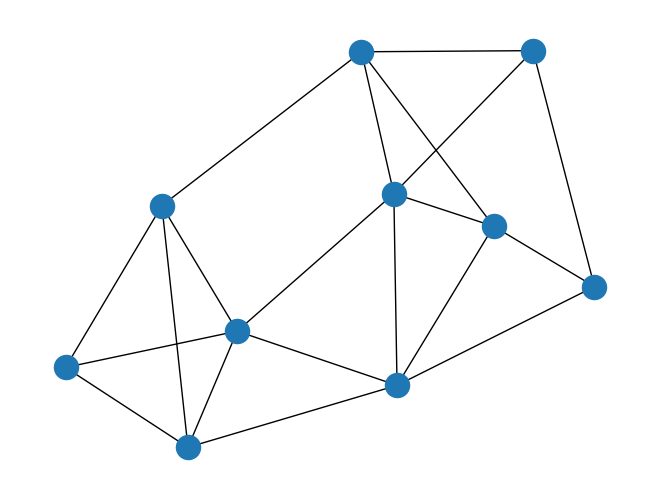

In [ ]:
n = 10
k = 4
p = 0.05

G_ws = create_ws_graph(n, k, p)

print_graph_stats(G_ws)

print(f'G_ws is connected: {nx.is_connected(G_ws)}')
print(f'Average shortest-path length: {nx.average_shortest_path_length(G_ws)}')
print(f'Maximum G_ws degree: {max(dict(G_ws.degree()).values())}')
nx.draw(G_ws)


1. Parameter k represents the number of nearests neighbors.

2. The rewiring probability p represents the probability that a node will be rewired when reached.

3. High clustering and small average path lengths are the characteristics that make this a small-world model.

4. The clustering for WS network is a lot higher (0.4967) than the ER network (0.0878)

# Part 6 - Compare the Three Models

| Model          | Nodes | Edges | Avg. Degree | Avg. Clustering | Max Degree |
|----------------|-------|-------|-------------|-----------------|------------|
| Erdos-Renyi    | 100   | 224   | 4.48        | 0.0423          | 10         |
| Albert         | 100   | 196   | 3.92        | 0.1634          | 36         |
| Watts-Strogatz | 100   | 20    | 4.0         | 0.4967          | 5          |

1. The Watts-Strogatz network has the highest clustering coefficient.

2. The Barabasi-Albert has the highest degree node.

3. The BA model appears to produce hubs.

4. The WA model produces a more uniform distribution of connections.

5. The WA model combines high clustering with relatively short paths.

# Part 7 - Degree Distribution

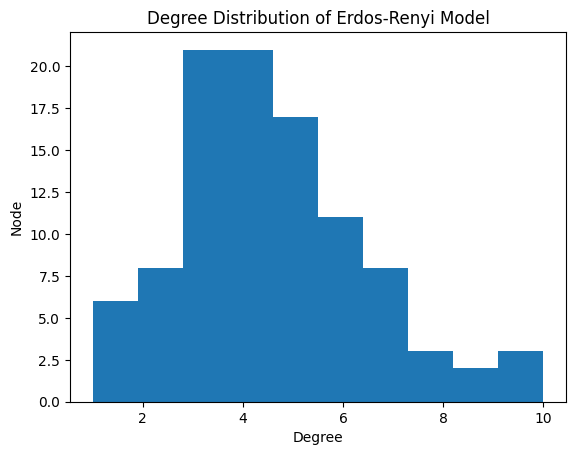

In [53]:
node_deg_er = dict(nx.degree(G_er))
node_deg_ba = dict(nx.degree(G_ba))
node_deg_ws = dict(nx.degree(G_ws))

# Erdo-Renyi plot
fig, ax = plt.subplots()

ax.hist(x=node_deg_er.values())
ax.set_title('Degree Distribution of Erdos-Renyi Model')
ax.set_xlabel('Degree')
ax.set_ylabel('Amount')

plt.show()


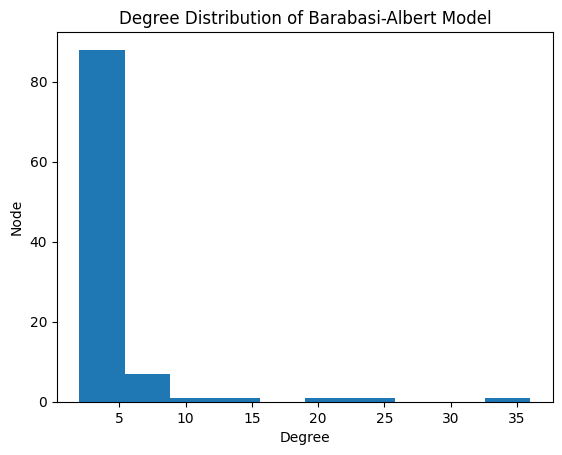

In [49]:
# Barabasi-Albert plot
fig, ax = plt.subplots()
ax.hist(x=node_deg_ba.values())
ax.set_title('Degree Distribution of Barabasi-Albert Model')
ax.set_xlabel('Degree')
ax.set_ylabel('Amount')

plt.show()

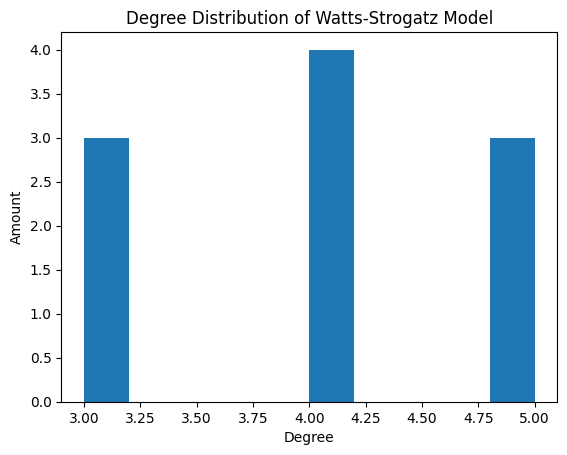

In [56]:
# Watts-Strogatz
fig, ax = plt.subplots()
ax.hist(x=node_deg_ws.values())
ax.set_title('Degree Distribution of Watts-Strogatz Model')
ax.set_xlabel('Degree')
ax.set_ylabel('Amount')

plt.show()

1. Erdos-Renyi degree distribution looks like a normal distribution

2. There are a higher amount of nodes with a low degree compared compared to the Erdos-Renyi model.

3. Yes, there are a few nodes that have a degree of 20 or higher which is larger than what most nodes have.

4. Watts-Strogatz shows a distribution that is almost uniform. Most nodes have the same degree.

# Part 8 - AI Use Documentation

1. what is the difference between G = nx.erdos_renyi_graph(n, p, seed=SEED) and the gnp_random_graph()?

2. The AI told me that they are essentially the same graph and that erdos_renyi is just an alias for gnp_random_graph.

3. I verified that this was correct by checking both functions outputs.

4. I mainly asked this question because the networkx documentation was showing the gnp_random_graph function but then I found the erdos_renyi_graph function and wondered if they differed somehow. The AI didn't suggest anything but I ended up using erdos_renyi.

# Part 9 - Reflection

Comparing an observed network with a network generated by a mathematical model will help us find out which characteristics match or differ between the two networks which can then be used to build models that are more accurate to the real world. Some of the characteristics that may differ include clustering, degree distribution, and shortest paths. One random graph model will not be appropriate for every real-world network because the real-world does not fit one singular model. Some networks may have higher connectivity than others or may contain less shortest paths than others. There is not a one-size fits all solution to real world models.